<a href="https://colab.research.google.com/github/adilbashir017-ux/Introduction-to-Cloud-Computing/blob/main/Tutorials/Tutorial_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
print(time.ctime())


Mon Nov  2 06:59:08 2026


In [1]:
!pip install numpy


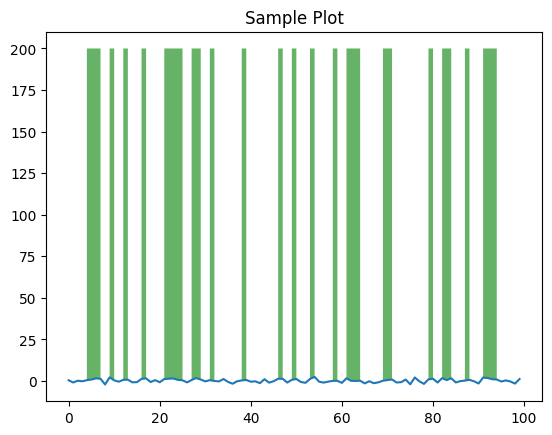

In [3]:
import numpy as np
from matplotlib import pyplot as plt

y = np.random.randn(100)
x = [x for x in range(len(y))]

plt.plot(x, y, '-')
plt.fill_between(x, y, 200, where = (y > 0), facecolor='g', alpha=0.6)

plt.title("Sample Plot")
plt.show()


In [ ]:
# @title Test form
Name = "" # @param {"type":"string"}
Family = "" # @param {"type":"string"}
Age = 0 # @param {"type":"number"}
Grade = 0 # @param {"type":"slider","min":0,"max":100,"step":1}
Gender = "Male" # @param ["Male","Famale"]


In [4]:


#@title Default title text
%%html
<style>
body {
  background-color: #f2bcca;
}
</style>
color = 'green' #@param ["red", "green", "blue"] print(color)
<svg xmlns="https://www.w3.org/2000/svg" viewBox="0 0 600 400" width="400" height="400">
   <rect x="10" y="00" width="300" height="100" rx="0" style="fill:orange; stroke:black; fill-opacity:1.0" />
   <rect x="10" y="100" width="300" height="100" rx="0" style="fill:white; stroke:black; fill-opacity:1.0;" />
   <rect x="10" y="200" width="300" height="100" rx="0" style="fill:green; stroke:black; fill-opacity:1.0;" />
</svg>



In [10]:
!ls "/content/drive/My Drive/Colab Notebooks"
from google.colab import drive
drive.mount('/content/drive')


 1.txt	'Copy of Lab1'	 Lab1.ipynb
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:

import os
os.chdir("/content/drive/MyDrive/Colab Notebooks")




In [25]:
with open('1.txt', 'r') as file:
    contents = file.read()
    print(contents)

﻿one
two
three


In [26]:

with open('example.txt', 'w') as file:
    file.write('This is some example text.')


In [29]:
import ipywidgets as widgets
from IPython.display import display
button = widgets.Button(description="Click Me!")
output = widgets.Output()

def on_button_clicked(b):
  # Display the message within the output widget.
  with output:
    with open('/content/drive/My Drive/Colab Notebooks/1.txt', 'r') as file:
      contents = file.read()
      print(contents)

button.on_click(on_button_clicked)
display(button, output)


Button(description='Click Me!', style=ButtonStyle())

Output()

In [30]:
import ipywidgets as widgets
slider = widgets.IntSlider(value=5, max=10)
display(slider)


IntSlider(value=5, max=10)

In [33]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Colab Notebooks/students.txt'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
file_path = '/content/drive/MyDrive/Colab Notebooks/Students.txt'

with open(file_path, 'r', encoding='utf-8') as file:
    for line in file:
        student = line.strip().split('|')
        print("First Name:", student[0])
        print("Last Name:", student[1])
        print("Email:", student[2])
        print("Courses:", student[3])
        print("Link:", student[4])
        print("--------------------")

First Name: Adel
Last Name: Bashir
Email: adel.bashir@e.braude.ac.il
Courses: Cloud Computing, Embedded Systems
Link: https://www.python.org
--------------------
First Name: Elias
Last Name: geraisy
Email: Elias.geraisy@braude.ac.il
Courses: Cloud Computing, Databases
Link: https://colab.research.google.com
--------------------


In [37]:
import ipywidgets as widgets
from IPython.display import display

# Read students from file
students = {}

with open(file_path, 'r', encoding='utf-8') as file:
    for line in file:
        data = line.strip().split('|')

        if len(data) >= 5:
            students[data[2]] = data


# Create dropdown
student_dropdown = widgets.Dropdown(
    options=[
        (data[0] + " " + data[1], email)
        for email, data in students.items()
    ],
    description='Student:'
)


# Create text fields
first_name = widgets.Text(description='First Name:', disabled=True)
last_name = widgets.Text(description='Last Name:', disabled=True)
email = widgets.Text(description='Email:', disabled=True)
courses = widgets.Textarea(description='Courses:', disabled=True)
link = widgets.Text(description='Link:', disabled=True)


# Update fields when selecting a student
def show_student(change=None):

    selected_email = student_dropdown.value
    student = students[selected_email]

    first_name.value = student[0]
    last_name.value = student[1]
    email.value = student[2]
    courses.value = student[3]
    link.value = student[4]


# Listen for dropdown changes
student_dropdown.observe(show_student, names='value')

# Favorite TV show field
favorite_show = widgets.Text(
    description='Favorite TV Show:'
)

# Update button
update_button = widgets.Button(
    description='Update',
    button_style='success'
)

# Status message
message = widgets.Output()


# Show saved favorite show when student changes
def show_favorite(change=None):
    student = students[student_dropdown.value]

    if len(student) > 5:
        favorite_show.value = student[5]
    else:
        favorite_show.value = ''


student_dropdown.observe(show_favorite, names='value')
show_favorite()


# Save updated student information
def update_student(button):

    selected_email = student_dropdown.value
    show = favorite_show.value.strip()

    with message:
        message.clear_output()

        if not show:
            print("Please enter a favorite TV show.")
            return

        if '|' in show:
            print("The | character is not allowed.")
            return

        student = students[selected_email]

        # Create updated record
        updated_student = student[:5] + [show]

        # Append new line to students.txt
        with open(file_path, 'a', encoding='utf-8') as file:
            file.write('\n' + '|'.join(updated_student))

        # Update student in memory
        students[selected_email] = updated_student

        print("Student updated successfully!")


# Connect button to function
update_button.on_click(update_student)

# Display first student
show_student()


# Display form
display(widgets.VBox([
    widgets.HTML("<h2>Student Information Form</h2>"),
    student_dropdown,
    first_name,
    last_name,
    email,
    courses,
    link,
    favorite_show,
    update_button,
    message
]))

In [38]:
with open(file_path, 'r', encoding='utf-8') as file:
    print(file.read())

Adel|Bashir|adel.bashir@e.braude.ac.il|Cloud Computing, Embedded Systems|https://www.python.org
Elias|geraisy|Elias.geraisy@braude.ac.il|Cloud Computing, Databases|https://colab.research.google.com

Adel|Bashir|adel.bashir@e.braude.ac.il|Cloud Computing, Embedded Systems|https://www.python.org|Sherlock Holmes
Elias|geraisy|Elias.geraisy@braude.ac.il|Cloud Computing, Databases|https://colab.research.google.com|Fauda


In [ ]:
import time
time.sleep(5)
print(time.ctime())


Mon Nov  2 06:59:13 2026
